# UC6: Mid-Campaign Distribution Shift

**Scientific question**: Does a mid-campaign noise increase causally degrade campaign outcome?
Does the degradation depend on *when* the shift occurs and *how large* it is?
Is BO more sensitive than random search?

**Key identification challenge**: The static backdoor adjustment set from UC2/UC3
`{budget, dim, ls, nl, snr}` is insufficient. Practitioners avoid BO when large shifts
are expected, so BO campaigns face systematically smaller shifts — the static estimator
overestimates the BO advantage.

**Estimator**: Interrupted Time Series (ITS) with DiD interpretation and cluster-robust SEs.
Outcome: `latent_outcome_t` (instantaneous step quality — directly captures the structural
shift effect without the accumulation bias of a running maximum).
The key coefficient is `strategy:log_step:post_shift` (three-way interaction).

---


In [14]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import networkx as nx
import statsmodels.formula.api as smf
from scipy import stats

from src.simulator import run_campaigns_uc6
from src.graphs import (
    uc6_dag, get_uc6_adjustment_set, get_uc6_static_adjustment_set,
    UC6_SHIFT_TIME_W, UC6_SHIFT_MAG_W, UC6_POST_SHIFT_W, UC6_SHIFT_MAG_SEL,
    UC6_SHIFT_MAG_MU, UC6_SHIFT_MAG_SIGMA, UC6_SHIFT_TIME_LOW, UC6_SHIFT_TIME_HIGH,
)

sns.set_theme(style='ticks', font_scale=1.1)
SEED, N, BUD = 42, 2000, 50
RESULTS_DIR = '../results'

print(f'UC6_SHIFT_TIME_W  = {UC6_SHIFT_TIME_W:+.2f}  (later shift → better outcome)')
print(f'UC6_SHIFT_MAG_W   = {UC6_SHIFT_MAG_W:+.2f}  (larger shift → worse outcome)')
print(f'UC6_POST_SHIFT_W  = {UC6_POST_SHIFT_W:+.2f}  (post-shift steps are harder)')
print(f'UC6_SHIFT_MAG_SEL = {UC6_SHIFT_MAG_SEL:+.2f}  (large shifts reduce P(BO))')
print(f'shift_time ~ Uniform({UC6_SHIFT_TIME_LOW}×budget, {UC6_SHIFT_TIME_HIGH}×budget)')
print(f'shift_magnitude ~ LogNormal(mu={UC6_SHIFT_MAG_MU:.3f}, sigma={UC6_SHIFT_MAG_SIGMA:.2f})  E[·]=3.0×')


UC6_SHIFT_TIME_W  = +0.05  (later shift → better outcome)
UC6_SHIFT_MAG_W   = -0.08  (larger shift → worse outcome)
UC6_POST_SHIFT_W  = -0.04  (post-shift steps are harder)
UC6_SHIFT_MAG_SEL = -0.15  (large shifts reduce P(BO))
shift_time ~ Uniform(0.2×budget, 0.8×budget)
shift_magnitude ~ LogNormal(mu=1.054, sigma=0.30)  E[·]=3.0×


## 1. UC6 DAG

Three new nodes are added to the UC2/UC3 DAG:
- `shift_time` — step at which noise increases (time-varying confounder)
- `shift_magnitude` — noise multiplier post-shift (also a confounder: large shifts reduce P(BO))
- `post_shift` — binary indicator: 1 if step > shift_time

The key new backdoor path is: **strategy ← shift_magnitude → norm_best_outcome_t**.
This path is blocked only by conditioning on `shift_magnitude`.


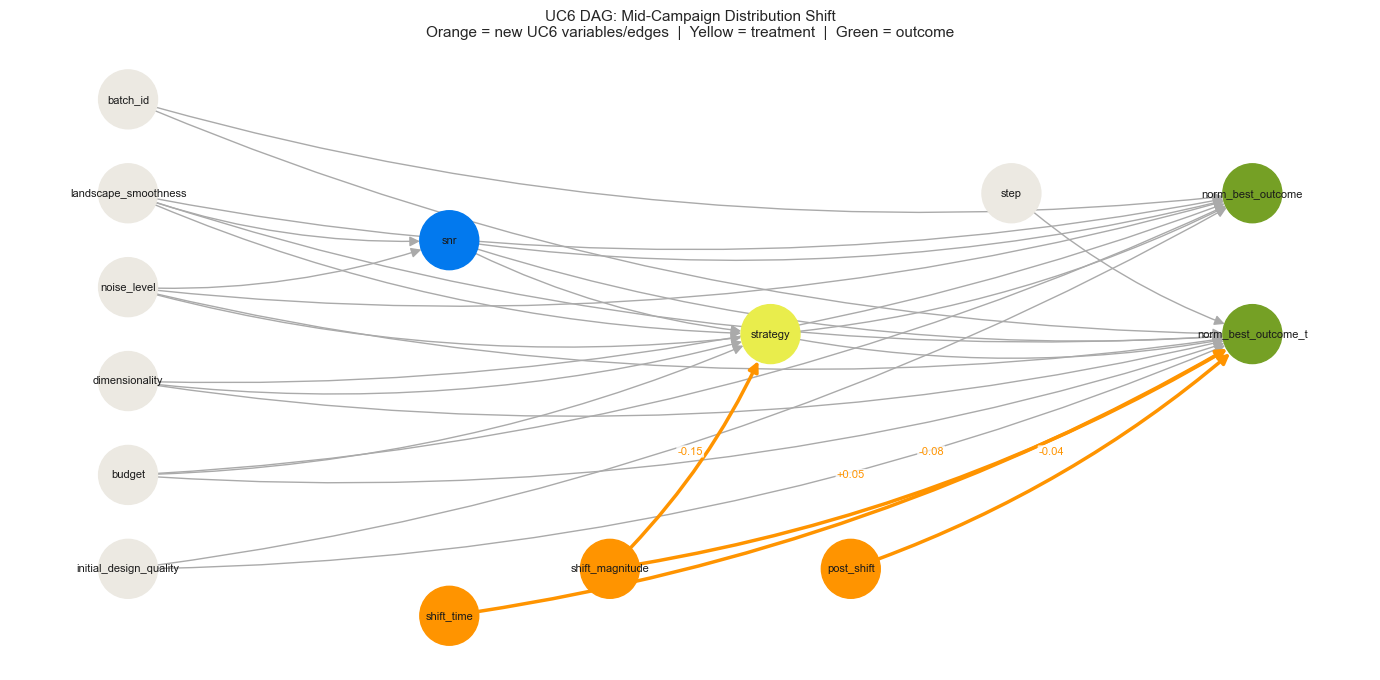

Saved uc6_dag.png

Static adjustment set (UC2): ['budget', 'dimensionality', 'landscape_smoothness', 'noise_level', 'snr']
Correct adjustment set (UC6): ['budget', 'dimensionality', 'landscape_smoothness', 'noise_level', 'shift_magnitude', 'shift_time', 'snr']


In [4]:
G = uc6_dag()

# ── Layout ────────────────────────────────────────────────────────────────────
# Fixed positions for a clean left-to-right causal flow
pos = {
    'batch_id':               (0.0, 4.5),
    'landscape_smoothness':   (0.0, 3.5),
    'noise_level':            (0.0, 2.5),
    'dimensionality':         (0.0, 1.5),
    'budget':                 (0.0, 0.5),
    'initial_design_quality': (0.0, -0.5),
    'snr':                    (2.0, 3.0),
    'strategy':               (4.0, 2.0),
    'shift_time':             (2.0, -1.0),
    'shift_magnitude':        (3.0, -0.5),
    'post_shift':             (4.5, -0.5),
    'step':                   (5.5, 3.5),
    'norm_best_outcome':      (7.0, 3.5),
    'norm_best_outcome_t':    (7.0, 2.0),
}

# ── Node colours ──────────────────────────────────────────────────────────────
uc6_new = {'shift_time', 'shift_magnitude', 'post_shift'}
node_colors = []
for n in G.nodes():
    if n in uc6_new:
        node_colors.append('#FF9400')   # orange  — new UC6 nodes
    elif n == 'strategy':
        node_colors.append('#E9ED4C')   # yellow  — treatment
    elif n in ('norm_best_outcome_t', 'norm_best_outcome'):
        node_colors.append('#75A025')   # green   — outcome
    elif n == 'snr':
        node_colors.append('#0279EE')   # blue    — key moderator
    elif n == 'post_shift':
        node_colors.append('#FD9BED')   # pink    — derived indicator
    else:
        node_colors.append('#ECE9E2')   # light grey — background confounders

# ── Edge colours ──────────────────────────────────────────────────────────────
uc6_new_edges = [
    ('shift_time',      'norm_best_outcome_t'),
    ('shift_magnitude', 'norm_best_outcome_t'),
    ('shift_magnitude', 'strategy'),
    ('post_shift',      'norm_best_outcome_t'),
    ('shift_time',      'post_shift'),
    ('shift_magnitude', 'post_shift'),
]
edge_colors = ['#FF9400' if (u, v) in uc6_new_edges else '#aaaaaa' for u, v in G.edges()]
edge_widths = [2.5 if (u, v) in uc6_new_edges else 1.0 for u, v in G.edges()]

# ── Draw ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
nx.draw_networkx(
    G, pos=pos, ax=ax,
    node_color=node_colors,
    edge_color=edge_colors,
    width=edge_widths,
    node_size=1800,
    font_size=8,
    arrows=True,
    arrowsize=15,
    connectionstyle='arc3,rad=0.1',
)

# Annotate key edge weights
edge_weight_labels = {
    ('shift_magnitude', 'strategy'):          f'{UC6_SHIFT_MAG_SEL:+.2f}',
    ('shift_time',      'norm_best_outcome_t'): f'{UC6_SHIFT_TIME_W:+.2f}',
    ('shift_magnitude', 'norm_best_outcome_t'): f'{UC6_SHIFT_MAG_W:+.2f}',
    ('post_shift',      'norm_best_outcome_t'): f'{UC6_POST_SHIFT_W:+.2f}',
}
for (u, v), label in edge_weight_labels.items():
    if u in pos and v in pos:
        mx = (pos[u][0] + pos[v][0]) / 2
        my = (pos[u][1] + pos[v][1]) / 2
        ax.text(mx, my, label, fontsize=8, color='#FF9400', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.8))

ax.set_title(
    'UC6 DAG: Mid-Campaign Distribution Shift\n'
    'Orange = new UC6 variables/edges  |  Yellow = treatment  |  Green = outcome',
    fontsize=11
)
ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_dag.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_dag.png')

# Print adjustment sets
print(f'\nStatic adjustment set (UC2): {get_uc6_static_adjustment_set()}')
print(f'Correct adjustment set (UC6): {get_uc6_adjustment_set()}')


## 2. Simulate UC6 campaigns

In [5]:
df = run_campaigns_uc6(n_campaigns=N, budget=BUD, seed=SEED)
print(f'Dataset: {len(df):,} rows × {len(df.columns)} columns')
print(f'Campaigns: {df["campaign_id"].nunique()}, Budget: {BUD} steps each')
print(f'Columns: {list(df.columns)}')

# Campaign-level summary (one row per campaign)
camp = (
    df.groupby('campaign_id')
      .agg(
          strategy=('strategy', 'first'),
          shift_time=('shift_time', 'first'),
          shift_magnitude=('shift_magnitude', 'first'),
          final_outcome=('norm_best_outcome_t', 'last'),
          snr=('snr', 'first'),
          landscape_smoothness=('landscape_smoothness', 'first'),
          noise_level=('noise_level', 'first'),
          dimensionality=('dimensionality', 'first'),
          budget=('budget', 'first'),
      )
      .reset_index()
)
camp['shift_time_frac'] = camp['shift_time'] / BUD
camp['strategy_label'] = camp['strategy'].map({1: 'BO', 0: 'RS'})

print(f'\nStrategy split: BO={camp["strategy"].mean():.1%}, RS={1-camp["strategy"].mean():.1%}')
print(f'Mean shift_time: {camp["shift_time"].mean():.1f} steps ({camp["shift_time_frac"].mean():.0%} of budget)')
print(f'Mean shift_magnitude: {camp["shift_magnitude"].mean():.2f}× (target E[·]=3.0×)')
print(f'Post-shift fraction of all steps: {df["post_shift"].mean():.1%}')
print(f'\nMedian effective_snr_t: pre-shift={df[df["post_shift"]==0]["effective_snr_t"].median():.2f}, '
      f'post-shift={df[df["post_shift"]==1]["effective_snr_t"].median():.2f}')


Dataset: 100,000 rows × 23 columns
Campaigns: 2000, Budget: 50 steps each
Columns: ['campaign_id', 'step', 'strategy', 'norm_best_outcome_t', 'latent_outcome_t', 'landscape_smoothness', 'budget', 'noise_level', 'dimensionality', 'initial_design_quality', 'batch_id', 'snr', 'snr_modulation', 'warmup_fraction', 't_warmup', 'g_t', 'shift_time', 'shift_magnitude', 'post_shift', 'effective_snr_t', 'effective_snr_mod_t', 'p_bo', 'batch_intercept']

Strategy split: BO=49.9%, RS=50.2%
Mean shift_time: 25.1 steps (50% of budget)
Mean shift_magnitude: 3.04× (target E[·]=3.0×)
Post-shift fraction of all steps: 50.8%

Median effective_snr_t: pre-shift=8.24, post-shift=2.93


## 3. Shift variable distributions

Three panels:
- **A**: `shift_time` distribution — should be approximately Uniform over [0.2, 0.8] × budget
- **B**: `shift_magnitude` distribution — should be LogNormal with E[·] ≈ 3.0×
- **C**: `shift_magnitude` by strategy — BO campaigns face smaller shifts (confounding)


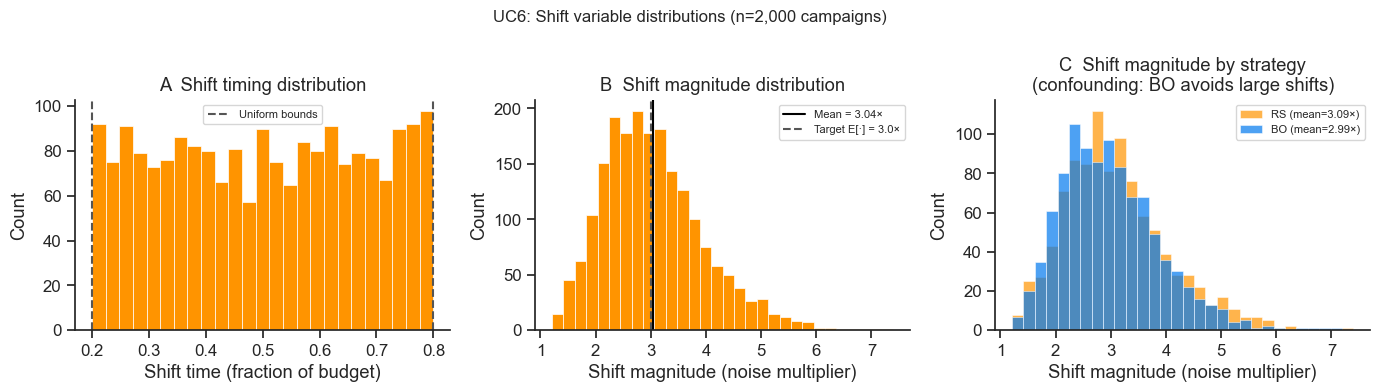

Saved uc6_shift_distributions.png

Confounding test (BO vs RS shift_magnitude):
  BO mean=2.987×, RS mean=3.095×, diff=+0.108×
  t-test: t=-2.644, p=0.0082


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle(f'UC6: Shift variable distributions (n={N:,} campaigns)', fontsize=12)

# ── A: shift_time distribution ────────────────────────────────────────────────
ax = axes[0]
ax.hist(camp['shift_time_frac'], bins=25, color='#FF9400', edgecolor='white', linewidth=0.5)
ax.axvline(UC6_SHIFT_TIME_LOW,  color='#555555', ls='--', lw=1.5, label='Uniform bounds')
ax.axvline(UC6_SHIFT_TIME_HIGH, color='#555555', ls='--', lw=1.5)
ax.set_xlabel('Shift time (fraction of budget)')
ax.set_ylabel('Count')
ax.set_title('A  Shift timing distribution')
ax.legend(fontsize=8)
sns.despine(ax=ax)

# ── B: shift_magnitude distribution ──────────────────────────────────────────
ax = axes[1]
sm_mean = camp['shift_magnitude'].mean()
ax.hist(camp['shift_magnitude'], bins=30, color='#FF9400', edgecolor='white', linewidth=0.5)
ax.axvline(sm_mean, color='black',   lw=1.5, label=f'Mean = {sm_mean:.2f}×')
ax.axvline(3.0,     color='#555555', lw=1.5, ls='--', label='Target E[·] = 3.0×')
ax.set_xlabel('Shift magnitude (noise multiplier)')
ax.set_ylabel('Count')
ax.set_title('B  Shift magnitude distribution')
ax.legend(fontsize=8)
sns.despine(ax=ax)

# ── C: shift_magnitude by strategy (confounding) ─────────────────────────────
ax = axes[2]
bo_sm = camp.loc[camp['strategy']==1, 'shift_magnitude']
rs_sm = camp.loc[camp['strategy']==0, 'shift_magnitude']
bins = np.linspace(camp['shift_magnitude'].min(), camp['shift_magnitude'].max(), 31)
ax.hist(rs_sm, bins=bins, color='#FF9400', alpha=0.7, edgecolor='white', linewidth=0.5,
        label=f'RS (mean={rs_sm.mean():.2f}×)')
ax.hist(bo_sm, bins=bins, color='#0279EE', alpha=0.7, edgecolor='white', linewidth=0.5,
        label=f'BO (mean={bo_sm.mean():.2f}×)')
ax.set_xlabel('Shift magnitude (noise multiplier)')
ax.set_ylabel('Count')
ax.set_title(f'C  Shift magnitude by strategy\n(confounding: BO avoids large shifts)')
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_shift_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_shift_distributions.png')

# Quantify confounding
t_stat, t_p = stats.ttest_ind(bo_sm, rs_sm)
print(f'\nConfounding test (BO vs RS shift_magnitude):')
print(f'  BO mean={bo_sm.mean():.3f}×, RS mean={rs_sm.mean():.3f}×, diff={rs_sm.mean()-bo_sm.mean():+.3f}×')
print(f'  t-test: t={t_stat:.3f}, p={t_p:.4f}')


## 4. Time-varying BO advantage collapse

Two panels:
- **A**: Mean `effective_snr_mod_t` by step and strategy — shows BO advantage collapsing post-shift
- **B**: Mean `norm_best_outcome_t` (running max) by step — convergence curves

The dotted vertical line marks the mean shift time across all campaigns.


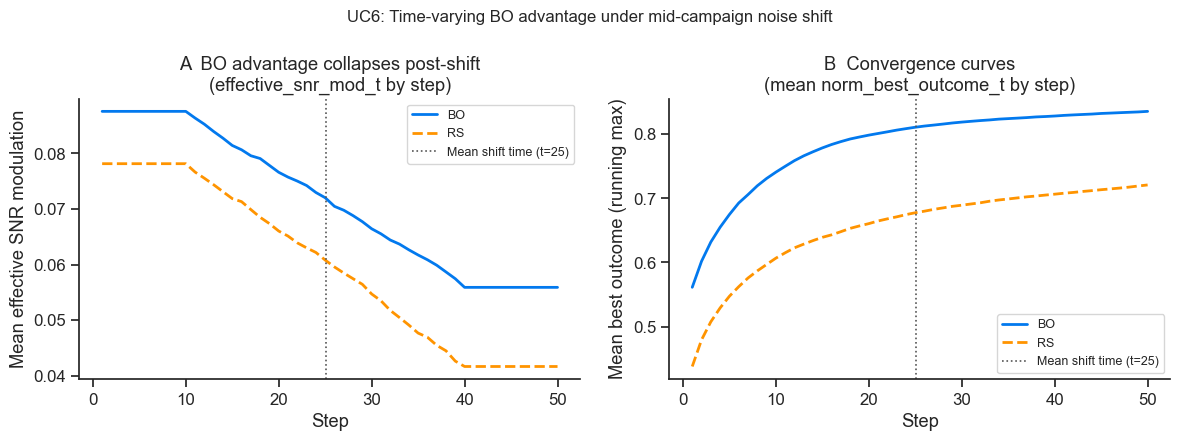

Saved uc6_convergence.png

Mean effective_snr_mod_t:
  Pre-shift:  RS=0.0771, BO=0.0880, advantage=+0.0109
  Post-shift: RS=0.0431, BO=0.0551, advantage=+0.0120
  Advantage drop: -0.0011

Median effective_snr_t: pre-shift=8.24, post-shift=2.93
(With 3× noise increase, many campaigns drop below τ=2.0 threshold)


In [7]:
# Aggregate by step and strategy
step_agg = (
    df.groupby(['step', 'strategy'])
      .agg(
          mean_snr_mod=('effective_snr_mod_t', 'mean'),
          mean_best=('norm_best_outcome_t', 'mean'),
      )
      .reset_index()
)
bo_agg = step_agg[step_agg['strategy']==1].sort_values('step')
rs_agg = step_agg[step_agg['strategy']==0].sort_values('step')
mean_shift_step = camp['shift_time'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle('UC6: Time-varying BO advantage under mid-campaign noise shift', fontsize=12)

# ── A: effective_snr_mod_t by step ────────────────────────────────────────────
ax = axes[0]
ax.plot(bo_agg['step'], bo_agg['mean_snr_mod'], color='#0279EE', lw=2, label='BO')
ax.plot(rs_agg['step'], rs_agg['mean_snr_mod'], color='#FF9400', lw=2, ls='--', label='RS')
ax.axvline(mean_shift_step, color='#555555', lw=1.2, ls=':', label=f'Mean shift time (t={mean_shift_step:.0f})')
ax.set_xlabel('Step')
ax.set_ylabel('Mean effective SNR modulation')
ax.set_title('A  BO advantage collapses post-shift\n(effective_snr_mod_t by step)')
ax.legend(fontsize=9)
sns.despine(ax=ax)

# ── B: convergence curves ─────────────────────────────────────────────────────
ax = axes[1]
ax.plot(bo_agg['step'], bo_agg['mean_best'], color='#0279EE', lw=2, label='BO')
ax.plot(rs_agg['step'], rs_agg['mean_best'], color='#FF9400', lw=2, ls='--', label='RS')
ax.axvline(mean_shift_step, color='#555555', lw=1.2, ls=':', label=f'Mean shift time (t={mean_shift_step:.0f})')
ax.set_xlabel('Step')
ax.set_ylabel('Mean best outcome (running max)')
ax.set_title('B  Convergence curves\n(mean norm_best_outcome_t by step)')
ax.legend(fontsize=9)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_convergence.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_convergence.png')

# Quantify the BO advantage drop
pre  = df[df['post_shift']==0].groupby('strategy')['effective_snr_mod_t'].mean()
post = df[df['post_shift']==1].groupby('strategy')['effective_snr_mod_t'].mean()
print(f'\nMean effective_snr_mod_t:')
print(f'  Pre-shift:  RS={pre[0]:.4f}, BO={pre[1]:.4f}, advantage={pre[1]-pre[0]:+.4f}')
print(f'  Post-shift: RS={post[0]:.4f}, BO={post[1]:.4f}, advantage={post[1]-post[0]:+.4f}')
print(f'  Advantage drop: {(pre[1]-pre[0]) - (post[1]-post[0]):+.4f}')

snr_pre  = df[df['post_shift']==0]['effective_snr_t'].median()
snr_post = df[df['post_shift']==1]['effective_snr_t'].median()
print(f'\nMedian effective_snr_t: pre-shift={snr_pre:.2f}, post-shift={snr_post:.2f}')
print(f'(With 3× noise increase, many campaigns drop below τ=2.0 threshold)')


## 5. Identification failure: static vs correct adjustment set

The static adjustment set `{budget, dim, ls, nl, snr}` from UC2/UC3 leaves the backdoor path
`strategy ← shift_magnitude → outcome` open. Because BO campaigns face smaller shifts
(selection weight = −0.15), the static estimator conflates the BO advantage with the
favourable shift environment, overestimating the true ATE.

Two panels:
- **A**: Bar chart comparing static vs correct ATE estimates with 95% CIs
- **B**: Shift magnitude distributions by strategy (the confounding mechanism)


Static ATE  (UC2 set):   0.0462  95% CI [0.0329, 0.0596]
Correct ATE (+shift):    0.0377  95% CI [0.0257, 0.0496]
Bias (static − correct): +0.0086
Direction: static OVERestimates BO advantage


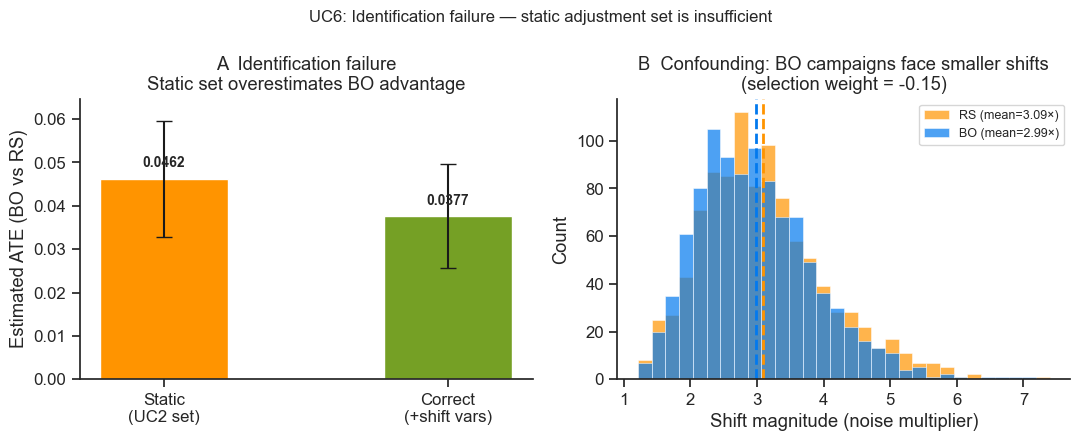

Saved uc6_identification.png


In [8]:
def std_col(series):
    m, s = series.mean(), series.std()
    return (series - m) / (s + 1e-12)

camp_reg = camp.copy()
for col in ['snr', 'landscape_smoothness', 'noise_level', 'dimensionality',
            'budget', 'shift_time', 'shift_magnitude']:
    camp_reg[f'{col}_z'] = std_col(camp_reg[col])

m_static = smf.ols(
    'final_outcome ~ strategy + snr_z + landscape_smoothness_z + '
    'noise_level_z + dimensionality_z + budget_z',
    data=camp_reg
).fit()

m_correct = smf.ols(
    'final_outcome ~ strategy + snr_z + landscape_smoothness_z + '
    'noise_level_z + dimensionality_z + budget_z + '
    'shift_time_z + shift_magnitude_z',
    data=camp_reg
).fit()

ate_s  = m_static.params['strategy']
ate_c  = m_correct.params['strategy']
ci_s   = m_static.conf_int().loc['strategy']
ci_c   = m_correct.conf_int().loc['strategy']

print(f'Static ATE  (UC2 set):   {ate_s:.4f}  95% CI [{ci_s[0]:.4f}, {ci_s[1]:.4f}]')
print(f'Correct ATE (+shift):    {ate_c:.4f}  95% CI [{ci_c[0]:.4f}, {ci_c[1]:.4f}]')
print(f'Bias (static − correct): {ate_s - ate_c:+.4f}')
print(f'Direction: static {"OVER" if ate_s > ate_c else "UNDER"}estimates BO advantage')

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('UC6: Identification failure — static adjustment set is insufficient', fontsize=12)

# Panel A: ATE bar chart
ax = axes[0]
labels = ['Static\n(UC2 set)', 'Correct\n(+shift vars)']
ates   = [ate_s, ate_c]
errs   = [[ate_s - ci_s[0], ate_c - ci_c[0]],
          [ci_s[1] - ate_s, ci_c[1] - ate_c]]
colors = ['#FF9400', '#75A025']
bars = ax.bar(labels, ates, color=colors, width=0.45,
              yerr=errs, capsize=6, error_kw={'lw': 1.5})
for bar, val in zip(bars, ates):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.002, f'{val:.4f}',
            ha='center', va='bottom', fontweight='bold', fontsize=10)
ax.set_ylabel('Estimated ATE (BO vs RS)')
ax.set_title('A  Identification failure\nStatic set overestimates BO advantage')
ax.set_ylim(0, max(ates) * 1.4)
sns.despine(ax=ax)

# Panel B: shift_magnitude by strategy
ax = axes[1]
bo_sm = camp.loc[camp['strategy']==1, 'shift_magnitude']
rs_sm = camp.loc[camp['strategy']==0, 'shift_magnitude']
bins = np.linspace(camp['shift_magnitude'].min(), camp['shift_magnitude'].max(), 31)
ax.hist(rs_sm, bins=bins, color='#FF9400', alpha=0.7, edgecolor='white', linewidth=0.5,
        label=f'RS (mean={rs_sm.mean():.2f}×)')
ax.hist(bo_sm, bins=bins, color='#0279EE', alpha=0.7, edgecolor='white', linewidth=0.5,
        label=f'BO (mean={bo_sm.mean():.2f}×)')
ax.axvline(rs_sm.mean(), color='#FF9400', lw=2, ls='--')
ax.axvline(bo_sm.mean(), color='#0279EE', lw=2, ls='--')
ax.set_xlabel('Shift magnitude (noise multiplier)')
ax.set_ylabel('Count')
ax.set_title(f'B  Confounding: BO campaigns face smaller shifts\n(selection weight = {UC6_SHIFT_MAG_SEL:+.2f})')
ax.legend(fontsize=9)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_identification.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_identification.png')


## 6. ITS/DiD estimator

Outcome: **`latent_outcome_t`** (instantaneous step quality).
Using a running maximum (`norm_best_outcome_t`) as the outcome would absorb the shift effect
into pre-shift accumulation, masking the structural degradation signal.

Model:
```
latent_outcome_t ~ strategy + log_step + strategy:log_step
                 + post_shift + post_shift:strategy + post_shift:log_step
                 + post_shift:strategy:log_step          ← key DiD term
                 + [standardised covariates]
```

Standard errors are clustered by `campaign_id` (cluster-robust).

Two panels:
- **A**: Coefficient forest plot (cluster-robust 95% CIs)
- **B**: Predicted convergence curves (mean covariates)


ITS/DiD on latent_outcome_t  R²=0.8737  n=100,000
Cluster-robust SEs (clustered by campaign_id)
Term                                         Coef   p-value   Sig
-----------------------------------------------------------------
BO baseline advantage                      0.0137    0.0458     *
RS convergence rate                        0.0840    0.0000   ***
Post-shift level drop                     -0.0642    0.0001   ***
BO convergence rate advantage              0.0217    0.0000   ***
BO post-shift level change                 0.0107    0.7238  n.s.
RS rate change post-shift                  0.0097    0.0160     *
BO rate advantage post-shift (key DiD term)  -0.0140    0.0470     *

Key DiD term: strategy:log_step:post_shift = -0.0140  (p=0.0470)
Interpretation: BO convergence rate advantage shrinks post-shift.


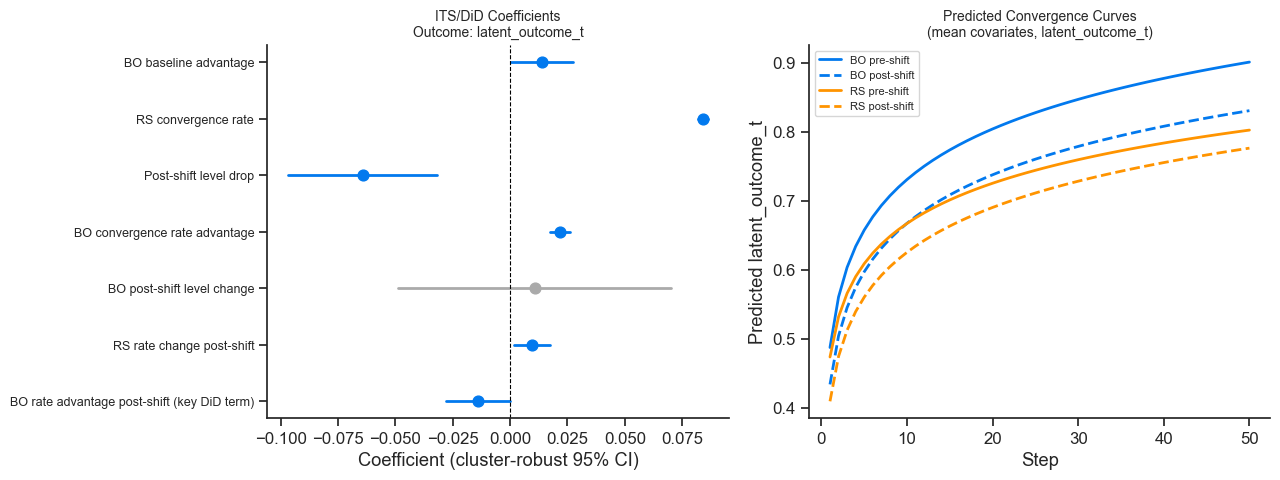

Saved uc6_its_model.png


In [9]:
df_its = df.copy()
df_its['log_step'] = np.log(df_its['step'].astype(float))
for col, alias in [('landscape_smoothness','ls_s'), ('noise_level','nl_s'),
                   ('budget','bud_s'), ('dimensionality','dim_s'),
                   ('snr','snr_s'), ('shift_time','shift_time_s'),
                   ('shift_magnitude','shift_mag_s')]:
    m, s = df_its[col].mean(), df_its[col].std()
    df_its[alias] = (df_its[col] - m) / (s + 1e-12)

its_formula = (
    'latent_outcome_t ~ strategy + log_step + strategy:log_step '
    '+ post_shift + post_shift:strategy + post_shift:log_step '
    '+ post_shift:strategy:log_step '
    '+ ls_s + nl_s + bud_s + dim_s + snr_s + shift_time_s + shift_mag_s'
)
m_its = smf.ols(its_formula, data=df_its).fit(
    cov_type='cluster', cov_kwds={'groups': df_its['campaign_id']}
)

key_terms = {
    'strategy':                    'BO baseline advantage',
    'log_step':                    'RS convergence rate',
    'post_shift':                  'Post-shift level drop',
    'strategy:log_step':           'BO convergence rate advantage',
    'post_shift:strategy':         'BO post-shift level change',
    'post_shift:log_step':         'RS rate change post-shift',
    'post_shift:strategy:log_step':'BO rate advantage post-shift (key DiD term)',
}

print(f'ITS/DiD on latent_outcome_t  R²={m_its.rsquared:.4f}  n={len(df_its):,}')
print(f'Cluster-robust SEs (clustered by campaign_id)')
print(f'{"Term":<40} {"Coef":>8}  {"p-value":>8}  {"Sig":>4}')
print('-' * 65)
for term, label in key_terms.items():
    if term in m_its.params:
        c = m_its.params[term]; p = m_its.pvalues[term]
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
        print(f'{label:<40} {c:>8.4f}  {p:>8.4f}  {sig:>4}')

did_coef = m_its.params['post_shift:strategy:log_step']
did_p    = m_its.pvalues['post_shift:strategy:log_step']
print(f'\nKey DiD term: strategy:log_step:post_shift = {did_coef:.4f}  (p={did_p:.4f})')
print('Interpretation: BO convergence rate advantage shrinks post-shift.')

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: forest plot
ax = axes[0]
terms  = list(key_terms.keys())
labels = [key_terms[t] for t in terms]
coefs  = [m_its.params[t] for t in terms]
ci_lo  = [m_its.conf_int().loc[t, 0] for t in terms]
ci_hi  = [m_its.conf_int().loc[t, 1] for t in terms]
pvals  = [m_its.pvalues[t] for t in terms]
colors = ['#0279EE' if p < 0.05 else '#aaaaaa' for p in pvals]

for i, (c, lo, hi, col) in enumerate(zip(coefs, ci_lo, ci_hi, colors)):
    ax.plot([lo, hi], [i, i], color=col, lw=2, zorder=1)
    ax.scatter([c], [i], color=col, s=60, zorder=2)

ax.axvline(0, color='black', lw=0.8, ls='--')
ax.set_yticks(range(len(terms)))
ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('Coefficient (cluster-robust 95% CI)')
ax.set_title('ITS/DiD Coefficients\nOutcome: latent_outcome_t', fontsize=10)
ax.invert_yaxis()
sns.despine(ax=ax)

# Panel B: predicted convergence curves
ax2 = axes[1]
steps = np.arange(1, BUD + 1)
log_steps = np.log(steps.astype(float))
b = m_its.params

for strat, label, col in [('BO', 'BO', '#0279EE'), ('RS', 'RS', '#FF9400')]:
    s_ind = 1.0 if strat == 'BO' else 0.0
    pre  = (b['Intercept']
            + s_ind * b['strategy']
            + log_steps * (b['log_step'] + s_ind * b['strategy:log_step']))
    post = (pre
            + b['post_shift']
            + s_ind * b.get('post_shift:strategy', 0)
            + log_steps * (b['post_shift:log_step']
                           + s_ind * b.get('post_shift:strategy:log_step', 0)))
    ax2.plot(steps, pre,  color=col, lw=2,       label=f'{label} pre-shift')
    ax2.plot(steps, post, color=col, lw=2, ls='--', label=f'{label} post-shift')

ax2.set_xlabel('Step')
ax2.set_ylabel('Predicted latent_outcome_t')
ax2.set_title('Predicted Convergence Curves\n(mean covariates, latent_outcome_t)', fontsize=10)
ax2.legend(fontsize=8)
sns.despine(ax=ax2)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_its_model.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_its_model.png')


## 7. Design rules

Three panels quantifying the four design rules:
- **A** (DR-UC6-A): Final outcome by shift timing quartile — earlier shifts → worse outcomes
- **B** (DR-UC6-A): Final outcome by shift magnitude quartile — larger shifts → worse outcomes
- **C** (DR-UC6-B): Per-step latent improvement rate pre vs post shift, by strategy — BO more sensitive


Design rules summary:

DR-UC6-A: Earlier shifts cause more degradation
  Final outcome by shift timing: {'Q1\n(early)': 0.7363, 'Q2': 0.7683, 'Q3': 0.7894, 'Q4\n(late)': 0.8186}
  Q1 (early) vs Q4 (late): 0.7363 vs 0.8186

DR-UC6-A (cont.): Larger shifts cause more degradation
  Final outcome by shift magnitude: {'Q1\n(small)': 0.8453, 'Q2': 0.8046, 'Q3': 0.7704, 'Q4\n(large)': 0.6924}
  Q1 (small) vs Q4 (large): 0.8453 vs 0.6924

DR-UC6-B: BO is more sensitive to noise shifts than RS
  Improvement rate drop: BO=0.01231, RS=0.00915
  BO/RS sensitivity ratio: 1.35×

DR-UC6-C: Static adjustment set overestimates BO advantage
  Bias = +0.0086 (static − correct)

DR-UC6-D: Monitor GP residual variance to detect shifts
  Post-shift SNR threshold: τ = 2.0
  Median post-shift SNR in simulation: 2.93


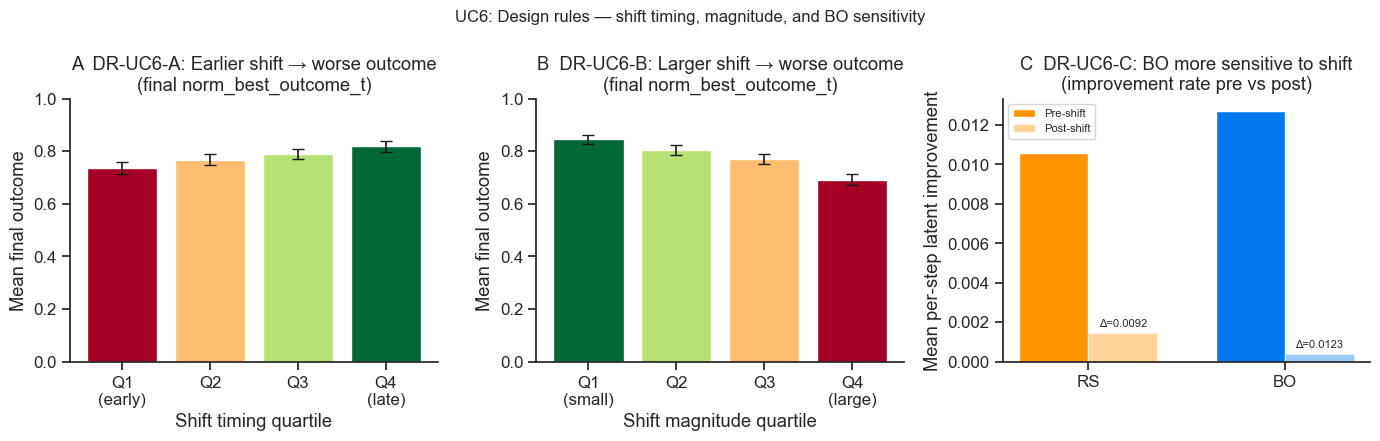

Saved uc6_design_rules.png


In [10]:
# ── DR-UC6-A: shift timing and magnitude effects ───────────────────────────────
camp['st_q']  = pd.qcut(camp['shift_time_frac'],  4, labels=['Q1\n(early)', 'Q2', 'Q3', 'Q4\n(late)'])
camp['sm_q']  = pd.qcut(camp['shift_magnitude'],  4, labels=['Q1\n(small)', 'Q2', 'Q3', 'Q4\n(large)'])

st_means = camp.groupby('st_q', observed=True)['final_outcome'].agg(['mean', 'sem'])
sm_means = camp.groupby('sm_q', observed=True)['final_outcome'].agg(['mean', 'sem'])

# ── DR-UC6-B: per-step improvement rate pre vs post shift ─────────────────────
df_s = df.sort_values(['campaign_id', 'step']).copy()
df_s['latent_diff'] = df_s.groupby('campaign_id')['latent_outcome_t'].diff()
rate_agg = (
    df_s.dropna(subset=['latent_diff'])
        .groupby(['strategy', 'post_shift'])['latent_diff']
        .agg(['mean', 'sem'])
        .reset_index()
)
rate_agg['label'] = rate_agg['strategy'].map({1: 'BO', 0: 'RS'})
rate_agg['period'] = rate_agg['post_shift'].map({0: 'Pre-shift', 1: 'Post-shift'})

bo_pre  = rate_agg.query('strategy==1 and post_shift==0')['mean'].values[0]
bo_post = rate_agg.query('strategy==1 and post_shift==1')['mean'].values[0]
rs_pre  = rate_agg.query('strategy==0 and post_shift==0')['mean'].values[0]
rs_post = rate_agg.query('strategy==0 and post_shift==1')['mean'].values[0]
bo_drop = bo_pre - bo_post
rs_drop = rs_pre - rs_post

print('Design rules summary:')
print()
print('DR-UC6-A: Earlier shifts cause more degradation')
print(f'  Final outcome by shift timing: {dict(st_means["mean"].round(4))}')
print(f'  Q1 (early) vs Q4 (late): {st_means["mean"].iloc[0]:.4f} vs {st_means["mean"].iloc[-1]:.4f}')
print()
print('DR-UC6-A (cont.): Larger shifts cause more degradation')
print(f'  Final outcome by shift magnitude: {dict(sm_means["mean"].round(4))}')
print(f'  Q1 (small) vs Q4 (large): {sm_means["mean"].iloc[0]:.4f} vs {sm_means["mean"].iloc[-1]:.4f}')
print()
print('DR-UC6-B: BO is more sensitive to noise shifts than RS')
print(f'  Improvement rate drop: BO={bo_drop:.5f}, RS={rs_drop:.5f}')
print(f'  BO/RS sensitivity ratio: {bo_drop/rs_drop:.2f}×')
print()
print('DR-UC6-C: Static adjustment set overestimates BO advantage')
print(f'  Bias = {ate_s - ate_c:+.4f} (static − correct)')
print()
print('DR-UC6-D: Monitor GP residual variance to detect shifts')
print(f'  Post-shift SNR threshold: τ = 2.0')
print(f'  Median post-shift SNR in simulation: {df[df["post_shift"]==1]["effective_snr_t"].median():.2f}')

# ── Figure ────────────────────────────────────────────────────────────────────
cmap_timing = plt.cm.RdYlGn
cmap_mag    = plt.cm.RdYlGn_r

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
fig.suptitle('UC6: Design rules — shift timing, magnitude, and BO sensitivity', fontsize=12)

# Panel A: shift timing
ax = axes[0]
n_q = len(st_means)
bar_colors = [cmap_timing(i / (n_q - 1)) for i in range(n_q)]
ax.bar(st_means.index, st_means['mean'], color=bar_colors,
       yerr=st_means['sem'] * 1.96, capsize=4, error_kw={'lw': 1.2})
ax.set_xlabel('Shift timing quartile')
ax.set_ylabel('Mean final outcome')
ax.set_title('A  DR-UC6-A: Earlier shift → worse outcome\n(final norm_best_outcome_t)')
ax.set_ylim(0, 1)
sns.despine(ax=ax)

# Panel B: shift magnitude
ax = axes[1]
bar_colors_m = [cmap_mag(i / (n_q - 1)) for i in range(n_q)]
ax.bar(sm_means.index, sm_means['mean'], color=bar_colors_m,
       yerr=sm_means['sem'] * 1.96, capsize=4, error_kw={'lw': 1.2})
ax.set_xlabel('Shift magnitude quartile')
ax.set_ylabel('Mean final outcome')
ax.set_title('B  DR-UC6-B: Larger shift → worse outcome\n(final norm_best_outcome_t)')
ax.set_ylim(0, 1)
sns.despine(ax=ax)

# Panel C: BO vs RS sensitivity
ax = axes[2]
x = np.array([0, 1])  # RS, BO
pre_vals  = [rs_pre,  bo_pre]
post_vals = [rs_post, bo_post]
drops     = [rs_drop, bo_drop]
bar_w = 0.35
bars_pre  = ax.bar(x - bar_w/2, pre_vals,  bar_w, color=['#FF9400', '#0279EE'],
                   label='Pre-shift', alpha=1.0)
bars_post = ax.bar(x + bar_w/2, post_vals, bar_w, color=['#FF9400', '#0279EE'],
                   label='Post-shift', alpha=0.4)
for xi, drop in zip(x, drops):
    ax.text(xi + bar_w/2, post_vals[int(xi)] + 0.0002, f'Δ={drop:.4f}',
            ha='center', va='bottom', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(['RS', 'BO'])
ax.set_ylabel('Mean per-step latent improvement')
ax.set_title(f'C  DR-UC6-C: BO more sensitive to shift\n(improvement rate pre vs post)')
ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_design_rules.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved uc6_design_rules.png')


## 8. Latent shift detection and causal estimation under unknown `shift_time`

In practice, `shift_time` is **not observed** — the practitioner must infer it from
campaign data. This section asks:

1. **How accurately can we detect the shift?** (oracle vs realistic detectors)
2. **How does detection error propagate into the causal estimate?** (plug-in vs MI)
3. **What design rules follow from the detection-lag sensitivity?**

### Detectors
- **Oracle**: PELT on `effective_snr_mod_t` (standardised per campaign) — upper bound
- **Realistic**: PELT on squared rolling OLS residuals of `latent_outcome_t` — practitioner-accessible
- **BOCPD**: Bayesian Online Changepoint Detection (Adams & MacKay 2007) run on both signals;
  posterior over `shift_time` used for multiple imputation

### Estimators
- **Oracle ITS**: true `shift_time` from simulator
- **Plug-in ITS**: realistic PELT point estimate (NaN → midpoint fallback)
- **MI ITS**: BOCPD posterior + Rubin's rules (B=50 imputations)


In [ ]:
# ── Install ruptures (PELT) if not already available ─────────────────────────
import importlib, subprocess, sys as _sys
if importlib.util.find_spec('ruptures') is None:
    subprocess.run([_sys.executable, '-m', 'pip', 'install', 'ruptures', '-q'], check=True)

import ruptures as rpt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats

from src.graphs import UC6_SHIFT_TIME_LOW, UC6_SHIFT_TIME_HIGH

sns.set_theme(style='ticks', font_scale=1.1)
SEED, N, BUD = 42, 2000, 50
RESULTS_DIR = '../'

# ── BOCPD implementation (Adams & MacKay 2007) ────────────────────────────────
def bocpd_posterior(signal, hazard=1/50, mu0=0.0, kappa0=1.0, alpha0=1.0, beta0=1.0):
    """
    Bayesian Online Changepoint Detection.
    Returns run-length posterior at each time step.
    signal: 1-D array of length T
    Returns: (T+1, T+1) matrix R where R[t, r] = P(run_length=r at time t)
    """
    T = len(signal)
    R = np.zeros((T + 1, T + 1))
    R[0, 0] = 1.0

    # Sufficient statistics for Normal-Gamma predictive
    mu    = np.full(T + 1, mu0)
    kappa = np.full(T + 1, kappa0)
    alpha = np.full(T + 1, alpha0)
    beta  = np.full(T + 1, beta0)

    for t in range(1, T + 1):
        x = signal[t - 1]

        # Predictive probability under Student-t
        pred_var = beta * (kappa + 1) / (alpha * kappa)
        pred_df  = 2 * alpha
        from scipy.stats import t as t_dist
        pred_prob = t_dist.pdf(x, df=pred_df, loc=mu, scale=np.sqrt(pred_var))

        # Growth probabilities (run continues)
        R[t, 1:t + 1] = R[t - 1, :t] * pred_prob[:t] * (1 - hazard)
        # Changepoint probability (run resets)
        R[t, 0] = np.sum(R[t - 1, :t] * pred_prob[:t]) * hazard

        # Normalise
        norm = R[t, :t + 1].sum()
        if norm > 0:
            R[t, :t + 1] /= norm

        # Update sufficient statistics
        kappa_new = kappa[:t] + 1
        mu_new    = (kappa[:t] * mu[:t] + x) / kappa_new
        alpha_new = alpha[:t] + 0.5
        beta_new  = beta[:t] + (kappa[:t] * (x - mu[:t])**2) / (2 * kappa_new)

        mu[1:t + 1]    = mu_new
        kappa[1:t + 1] = kappa_new
        alpha[1:t + 1] = alpha_new
        beta[1:t + 1]  = beta_new

    return R


def bocpd_shift_posterior(signal, hazard=1/50, **kwargs):
    """
    Convert BOCPD run-length posterior to a posterior over shift_time.
    Returns: array of length T with P(shift at step t).
    """
    T = len(signal)
    R = bocpd_posterior(signal, hazard=hazard, **kwargs)
    # P(changepoint at step t) = R[t, 0]  (run length resets to 0)
    cp_prob = R[1:, 0]   # shape (T,)
    return cp_prob


# ── Build detection dataset ───────────────────────────────────────────────────
# One row per campaign with detection results from all four methods
print("Running detection on all campaigns...")
print("(This takes ~2-3 minutes for n=2,000 campaigns)")

rng_det = np.random.default_rng(SEED)
records = []

for cid, grp in df.groupby('campaign_id'):
    grp = grp.sort_values('step').reset_index(drop=True)
    T   = len(grp)
    true_st = int(grp['shift_time'].iloc[0])

    # ── Oracle signal: standardised effective_snr_mod_t ──────────────────────
    oracle_sig = grp['effective_snr_mod_t'].values.astype(float)
    oracle_sig = (oracle_sig - oracle_sig.mean()) / (oracle_sig.std() + 1e-12)

    # ── Realistic signal: squared rolling OLS residuals ──────────────────────
    # Fit OLS(latent_outcome_t ~ log_step) on a rolling window, take squared residuals
    log_steps = np.log(grp['step'].values.astype(float))
    y = grp['latent_outcome_t'].values.astype(float)
    window = 5
    resid_sq = np.zeros(T)
    for t in range(window, T):
        x_w = log_steps[max(0, t - window):t]
        y_w = y[max(0, t - window):t]
        if len(x_w) >= 2:
            X_w = np.column_stack([np.ones(len(x_w)), x_w])
            try:
                beta_w = np.linalg.lstsq(X_w, y_w, rcond=None)[0]
                resid_sq[t] = (y[t] - (beta_w[0] + beta_w[1] * log_steps[t]))**2
            except Exception:
                resid_sq[t] = 0.0
    realistic_sig = resid_sq

    # ── PELT detection ────────────────────────────────────────────────────────
    def pelt_detect(signal, pen=3.0):
        try:
            algo = rpt.Pelt(model='rbf', min_size=3, jump=1).fit(signal.reshape(-1, 1))
            bkps = algo.predict(pen=pen)
            # bkps[-1] is always T (end of signal), take the first real breakpoint
            real_bkps = [b for b in bkps if b < T]
            return float(real_bkps[0]) if real_bkps else np.nan
        except Exception:
            return np.nan

    oracle_pelt    = pelt_detect(oracle_sig,    pen=3.0)
    realistic_pelt = pelt_detect(realistic_sig, pen=3.0)

    # ── BOCPD detection ───────────────────────────────────────────────────────
    def bocpd_map(signal):
        try:
            cp_prob = bocpd_shift_posterior(signal, hazard=1.0/((UC6_SHIFT_TIME_HIGH - UC6_SHIFT_TIME_LOW)*BUD))
            return float(np.argmax(cp_prob) + 1)   # +1: 0-indexed argmax -> 1-indexed step
        except Exception:
            return np.nan

    def bocpd_probs(signal):
        try:
            return bocpd_shift_posterior(signal, hazard=1.0/((UC6_SHIFT_TIME_HIGH - UC6_SHIFT_TIME_LOW)*BUD))
        except Exception:
            return np.zeros(T)

    oracle_bocpd_map    = bocpd_map(oracle_sig)
    realistic_bocpd_map = bocpd_map(realistic_sig)
    realistic_bocpd_p   = bocpd_probs(realistic_sig)

    records.append({
        'campaign_id':          cid,
        'true_shift_time':      true_st,
        'snr':                  grp['snr'].iloc[0],
        'oracle_pelt':          oracle_pelt,
        'realistic_pelt':       realistic_pelt,
        'oracle_bocpd_map':     oracle_bocpd_map,
        'realistic_bocpd_map':  realistic_bocpd_map,
        'realistic_bocpd_probs': realistic_bocpd_p,
    })

det = pd.DataFrame(records)
print(f"Detection complete. Shape: {det.shape}")
print(f"Undetected (realistic PELT NaN): {det['realistic_pelt'].isna().mean():.1%}")


Running detection on all campaigns...
(This takes ~2-3 minutes for n=2,000 campaigns)
Detection complete. Shape: (2000, 8)
Undetected (realistic PELT NaN): 92.7%


### 8.1 Detection accuracy

Compare oracle vs realistic detectors across:
- Lag distribution (detected − true shift_time)
- Accuracy vs tolerance threshold
- MAD / within-±3 / undetected rate by SNR quartile


Detection accuracy summary (all lags in steps; negative = early, positive = late):
  Oracle PELT                    MAD=0.0  within±3=100%  mean_lag=+0.0  median_lag=+0.0  undetected=2%
  Oracle BOCPD MAP               MAD=10.0  within±3=17%  mean_lag=-1.4  median_lag=+3.0  undetected=0%
  Realistic PELT                 MAD=10.5  within±3=21%  mean_lag=-3.0  median_lag=-4.0  undetected=93%
  Realistic BOCPD MAP            MAD=12.0  within±3=16%  mean_lag=-11.2  median_lag=-12.0  undetected=0%

Realistic PELT mean lag = -3.0 steps → biased early (negative lag)
  → Plug-in ITS will INFLATE the DiD magnitude (more negative than oracle)


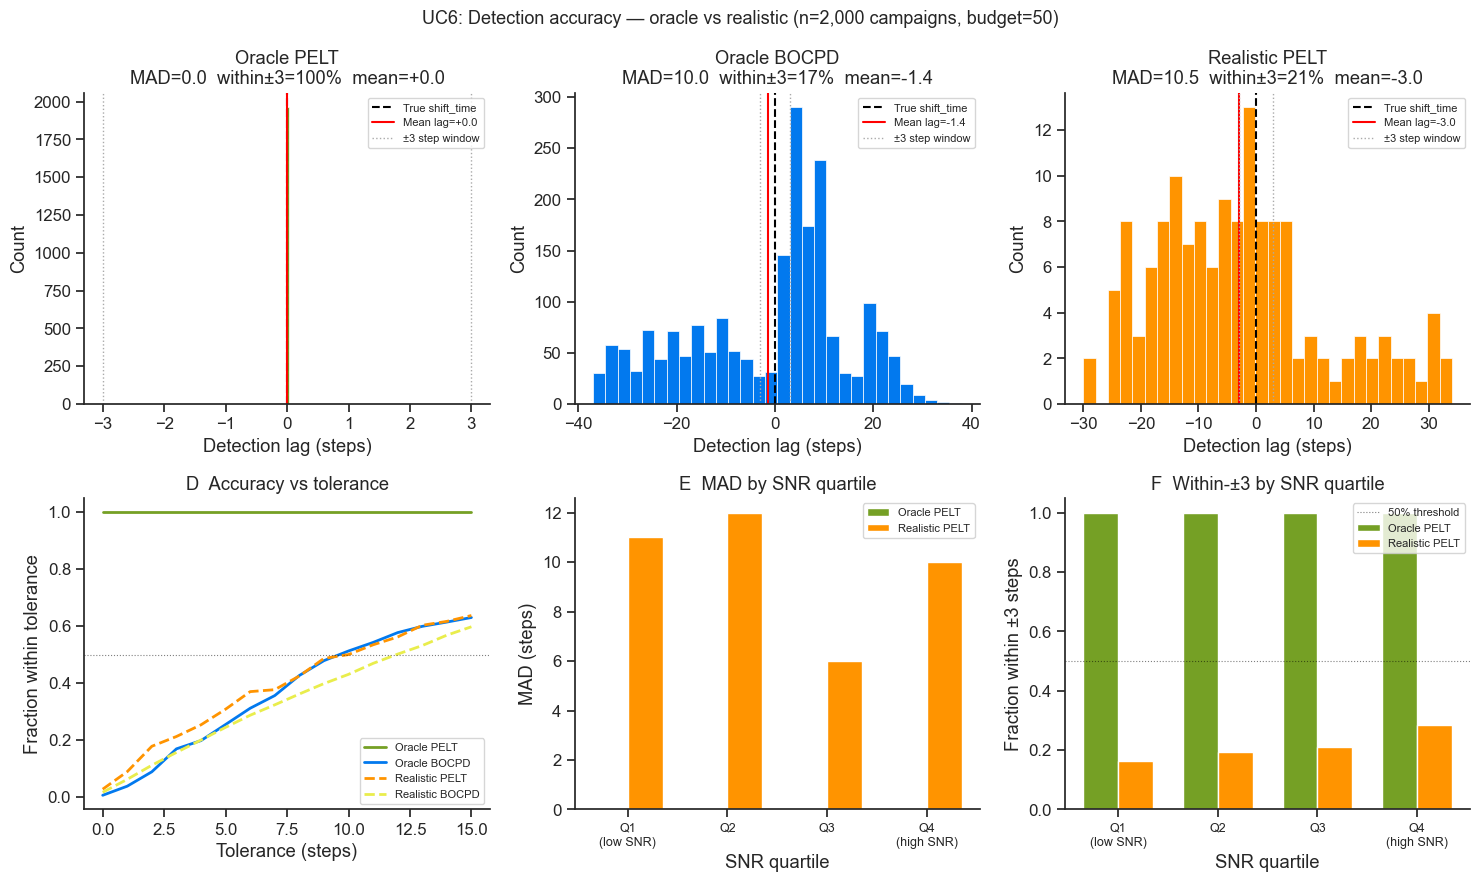

Saved uc6_detection_accuracy.png


In [15]:
# ── Compute detection lags ────────────────────────────────────────────────────
det['lag_oracle_pelt']    = det['oracle_pelt']    - det['true_shift_time']
det['lag_realistic_pelt'] = det['realistic_pelt'] - det['true_shift_time']
det['lag_oracle_bocpd']   = det['oracle_bocpd_map']    - det['true_shift_time']
det['lag_realistic_bocpd']= det['realistic_bocpd_map'] - det['true_shift_time']

# SNR quartile
det['snr_q'] = pd.qcut(det['snr'], 4, labels=['Q1\n(low SNR)', 'Q2', 'Q3', 'Q4\n(high SNR)'])

# ── Summary table ─────────────────────────────────────────────────────────────
def detection_summary(lag_col, name):
    lags = det[lag_col].dropna()
    mad    = lags.abs().median()
    w3     = (lags.abs() <= 3).mean()
    undet  = det[lag_col].isna().mean()
    mean_l = lags.mean()
    med_l  = lags.median()
    print(f"  {name:<30} MAD={mad:.1f}  within±3={w3:.0%}  "
          f"mean_lag={mean_l:+.1f}  median_lag={med_l:+.1f}  undetected={undet:.0%}")

print("Detection accuracy summary (all lags in steps; negative = early, positive = late):")
detection_summary('lag_oracle_pelt',     'Oracle PELT')
detection_summary('lag_oracle_bocpd',    'Oracle BOCPD MAP')
detection_summary('lag_realistic_pelt',  'Realistic PELT')
detection_summary('lag_realistic_bocpd', 'Realistic BOCPD MAP')

# ── Bias direction note ───────────────────────────────────────────────────────
# This is important for interpreting the plug-in ITS estimator:
# - If mean_lag < 0 (early detection): plug-in post_shift triggers too early
#   → more steps labelled post-shift → DiD inflated (more negative)
# - If mean_lag > 0 (late detection): plug-in post_shift triggers too late
#   → fewer steps labelled post-shift → DiD attenuated (less negative)
# The lag sweep in Section 9.3 confirms this relationship.
print()
pelt_mean = det['lag_realistic_pelt'].dropna().mean()
direction = "early (negative lag)" if pelt_mean < 0 else "late (positive lag)"
print(f"Realistic PELT mean lag = {pelt_mean:+.1f} steps → biased {direction}")
if pelt_mean < 0:
    print("  → Plug-in ITS will INFLATE the DiD magnitude (more negative than oracle)")
else:
    print("  → Plug-in ITS will ATTENUATE the DiD magnitude (less negative than oracle)")

# ── Figure: 6-panel detection accuracy ───────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle(f'UC6: Detection accuracy — oracle vs realistic (n={N:,} campaigns, budget={BUD})',
             fontsize=13)

# Row 1: lag histograms (oracle PELT, oracle BOCPD, realistic PELT)
for ax, lag_col, label, col in [
    (axes[0, 0], 'lag_oracle_pelt',    'Oracle PELT',    '#75A025'),
    (axes[0, 1], 'lag_oracle_bocpd',   'Oracle BOCPD',   '#0279EE'),
    (axes[0, 2], 'lag_realistic_pelt', 'Realistic PELT', '#FF9400'),
]:
    lags   = det[lag_col].dropna()
    mad    = lags.abs().median()
    w3     = (lags.abs() <= 3).mean()
    mean_l = lags.mean()
    ax.hist(lags, bins=30, color=col, edgecolor='white', linewidth=0.5)
    ax.axvline(0,       color='black',   lw=1.5, ls='--', label='True shift_time')
    ax.axvline(mean_l,  color='red',     lw=1.5, ls='-',  label=f'Mean lag={mean_l:+.1f}')
    ax.axvline(-3, color='#aaaaaa', lw=1.0, ls=':')
    ax.axvline(+3, color='#aaaaaa', lw=1.0, ls=':', label='±3 step window')
    ax.set_xlabel('Detection lag (steps)')
    ax.set_ylabel('Count')
    ax.set_title(f'{label}\nMAD={mad:.1f}  within±3={w3:.0%}  mean={mean_l:+.1f}')
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

# Row 2: accuracy vs tolerance + MAD/within-±3 by SNR quartile
ax = axes[1, 0]
tols = np.arange(0, 16)
for lag_col, label, col, ls in [
    ('lag_oracle_pelt',     'Oracle PELT',     '#75A025', '-'),
    ('lag_oracle_bocpd',    'Oracle BOCPD',    '#0279EE', '-'),
    ('lag_realistic_pelt',  'Realistic PELT',  '#FF9400', '--'),
    ('lag_realistic_bocpd', 'Realistic BOCPD', '#E9ED4C', '--'),
]:
    acc = [(det[lag_col].dropna().abs() <= t).mean() for t in tols]
    ax.plot(tols, acc, color=col, lw=2, ls=ls, label=label)
ax.axhline(0.5, color='black', lw=0.8, ls=':', alpha=0.5)
ax.set_xlabel('Tolerance (steps)')
ax.set_ylabel('Fraction within tolerance')
ax.set_title('D  Accuracy vs tolerance')
ax.legend(fontsize=8)
sns.despine(ax=ax)

snr_q_labels = det['snr_q'].cat.categories.tolist()
x = np.arange(len(snr_q_labels))
bar_w = 0.35

ax = axes[1, 1]
for offset, lag_col, label, col in [
    (-bar_w/2, 'lag_oracle_pelt',    'Oracle PELT',    '#75A025'),
    (+bar_w/2, 'lag_realistic_pelt', 'Realistic PELT', '#FF9400'),
]:
    mads = [det.loc[det['snr_q']==q, lag_col].dropna().abs().median()
            for q in snr_q_labels]
    ax.bar(x + offset, mads, bar_w, color=col, label=label)
ax.set_xticks(x); ax.set_xticklabels(snr_q_labels, fontsize=9)
ax.set_xlabel('SNR quartile'); ax.set_ylabel('MAD (steps)')
ax.set_title('E  MAD by SNR quartile'); ax.legend(fontsize=8)
sns.despine(ax=ax)

ax = axes[1, 2]
for offset, lag_col, label, col in [
    (-bar_w/2, 'lag_oracle_pelt',    'Oracle PELT',    '#75A025'),
    (+bar_w/2, 'lag_realistic_pelt', 'Realistic PELT', '#FF9400'),
]:
    w3s = [(det.loc[det['snr_q']==q, lag_col].dropna().abs() <= 3).mean()
           for q in snr_q_labels]
    ax.bar(x + offset, w3s, bar_w, color=col, label=label)
ax.axhline(0.5, color='black', lw=0.8, ls=':', alpha=0.5, label='50% threshold')
ax.set_xticks(x); ax.set_xticklabels(snr_q_labels, fontsize=9)
ax.set_xlabel('SNR quartile'); ax.set_ylabel('Fraction within ±3 steps')
ax.set_title('F  Within-±3 by SNR quartile'); ax.legend(fontsize=8)
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_detection_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved uc6_detection_accuracy.png")


### 8.2 Causal estimation under latent `shift_time`

Three estimators compared on the key DiD term (`strategy:log_step:post_shift`):

| Estimator | Description |
|---|---|
| **Oracle ITS** | True `shift_time` from simulator — upper bound |
| **Plug-in ITS** | Realistic PELT point estimate (NaN → midpoint fallback) |
| **MI ITS** | BOCPD posterior + Rubin's rules (B=50 imputations) |

Key question: does plug-in underestimate uncertainty? Does MI recover it?


In [16]:
def build_its_df(df, det_row, shift_time_col):
    """
    Rebuild the ITS panel dataset using a (possibly imputed) shift_time.
    shift_time_col: column name in det_row to use as shift_time.
    Returns df_its with post_shift recomputed from the imputed shift_time.
    """
    imputed_st = det_row.set_index('campaign_id')[shift_time_col]
    df_its = df.copy()
    df_its['shift_time_imputed'] = df_its['campaign_id'].map(imputed_st)
    df_its['post_shift_imp'] = (df_its['step'] > df_its['shift_time_imputed']).astype(int)
    df_its['log_step'] = np.log(df_its['step'].astype(float))
    for col, alias in [('landscape_smoothness','ls_s'), ('noise_level','nl_s'),
                       ('budget','bud_s'), ('dimensionality','dim_s'),
                       ('snr','snr_s'), ('shift_time','shift_time_s'),
                       ('shift_magnitude','shift_mag_s')]:
        m, s = df_its[col].mean(), df_its[col].std()
        df_its[alias] = (df_its[col] - m) / (s + 1e-12)
    return df_its


def fit_its(df_its, post_shift_col='post_shift_imp'):
    """Fit ITS/DiD on latent_outcome_t with cluster-robust SEs."""
    formula = (
        f'latent_outcome_t ~ strategy + log_step + strategy:log_step '
        f'+ {post_shift_col} + {post_shift_col}:strategy + {post_shift_col}:log_step '
        f'+ {post_shift_col}:strategy:log_step '
        f'+ ls_s + nl_s + bud_s + dim_s + snr_s + shift_time_s + shift_mag_s'
    )
    m = smf.ols(formula, data=df_its).fit(
        cov_type='cluster', cov_kwds={'groups': df_its['campaign_id']}
    )
    did_key = f'{post_shift_col}:strategy:log_step'
    coef = m.params[did_key]
    se   = m.bse[did_key]
    pval = m.pvalues[did_key]
    ci   = m.conf_int().loc[did_key]
    return {'coef': coef, 'se': se, 'pval': pval, 'ci_lo': ci[0], 'ci_hi': ci[1]}


# ── Estimator 1: Oracle ───────────────────────────────────────────────────────
df_its_oracle = df.copy()
df_its_oracle['post_shift_imp'] = df_its_oracle['post_shift']
df_its_oracle['log_step'] = np.log(df_its_oracle['step'].astype(float))
for col, alias in [('landscape_smoothness','ls_s'), ('noise_level','nl_s'),
                   ('budget','bud_s'), ('dimensionality','dim_s'),
                   ('snr','snr_s'), ('shift_time','shift_time_s'),
                   ('shift_magnitude','shift_mag_s')]:
    m_v, s_v = df_its_oracle[col].mean(), df_its_oracle[col].std()
    df_its_oracle[alias] = (df_its_oracle[col] - m_v) / (s_v + 1e-12)

res_oracle = fit_its(df_its_oracle)
print(f"Oracle ITS:    DiD coef={res_oracle['coef']:+.4f}  SE={res_oracle['se']:.4f}  p={res_oracle['pval']:.4f}")

# ── Estimator 2: Plug-in (realistic PELT) ────────────────────────────────────
det_plugin = det.copy()
midpoint = BUD * (UC6_SHIFT_TIME_LOW + UC6_SHIFT_TIME_HIGH) / 2
det_plugin['plugin_st'] = det_plugin['realistic_pelt'].fillna(midpoint)
df_its_plugin = build_its_df(df, det_plugin, 'plugin_st')
res_plugin = fit_its(df_its_plugin)
print(f"Plug-in ITS:   DiD coef={res_plugin['coef']:+.4f}  SE={res_plugin['se']:.4f}  p={res_plugin['pval']:.4f}")
print(f"  Bias (plug-in vs oracle): {res_plugin['coef'] - res_oracle['coef']:+.4f}")
print(f"  SE ratio (plug-in/oracle): {res_plugin['se'] / res_oracle['se']:.2f}x")


Oracle ITS:    DiD coef=-0.0140  SE=0.0071  p=0.0470
Plug-in ITS:   DiD coef=-0.0398  SE=0.0096  p=0.0000
  Bias (plug-in vs oracle): -0.0258
  SE ratio (plug-in/oracle): 1.36x


In [13]:
def rubin_pool(coefs, ses):
    """Pool B imputed estimates using Rubin's rules (1987)."""
    B = len(coefs)
    Q_bar = np.mean(coefs)
    U_bar = np.mean(ses**2)
    B_var = np.var(coefs, ddof=1)
    T_var = U_bar + (1 + 1/B) * B_var
    se_pool = np.sqrt(T_var)
    r_m = (1 + 1/B) * B_var / U_bar
    nu  = (B - 1) * (1 + 1/r_m)**2
    nu  = max(nu, 3)
    from scipy.stats import t as t_dist
    t_crit = t_dist.ppf(0.975, df=nu)
    return Q_bar, se_pool, Q_bar - t_crit*se_pool, Q_bar + t_crit*se_pool


# ── Estimator 3: Multiple Imputation (BOCPD posterior, B=50) ─────────────────
# The BOCPD posterior probs[i] = P(shift at step i+1) (1-indexed).
# We sample step numbers in [1..T] to match shift_time in the dataframe.
B_imp = 50
rng_mi = np.random.default_rng(SEED)
coefs_mi = np.zeros(B_imp)
ses_mi   = np.zeros(B_imp)

for b in range(B_imp):
    sampled_st = []
    for _, row in det.iterrows():
        probs = row['realistic_bocpd_probs']   # probs[i] = P(shift at step i+1)
        T_c   = len(probs)
        # steps are 1-indexed: step i+1 corresponds to probs[i]
        steps_1indexed = np.arange(1, T_c + 1)
        if probs.sum() > 0:
            st_sample = rng_mi.choice(steps_1indexed, p=probs / probs.sum())
        else:
            # Fallback: midpoint of valid window
            st_sample = int(BUD * (UC6_SHIFT_TIME_LOW + UC6_SHIFT_TIME_HIGH) / 2)
        sampled_st.append({'campaign_id': row['campaign_id'], 'imp_st': float(st_sample)})

    det_imp = pd.DataFrame(sampled_st)
    df_its_imp = build_its_df(df, det_imp, 'imp_st')
    res_b = fit_its(df_its_imp)
    coefs_mi[b] = res_b['coef']
    ses_mi[b]   = res_b['se']

    if (b + 1) % 10 == 0:
        print(f"  Imputation {b+1}/{B_imp}: coef={coefs_mi[b]:+.4f}")

Q_mi, se_mi, ci_lo_mi, ci_hi_mi = rubin_pool(coefs_mi, ses_mi)
print(f"\nMI ITS (B={B_imp}): DiD coef={Q_mi:+.4f}  SE={se_mi:.4f}  "
      f"95% CI [{ci_lo_mi:.4f}, {ci_hi_mi:.4f}]")
print(f"Bias (MI vs oracle): {Q_mi - res_oracle['coef']:+.4f}")

# ── Comparison table ──────────────────────────────────────────────────────────
print("\nEstimator comparison — key DiD term (strategy:log_step:post_shift):")
print(f"{'Estimator':<35} {'Coef':>8}  {'SE':>6}  {'95% CI':>22}  {'Bias':>8}")
print("-" * 85)
rows = [
    ('Oracle ITS (true shift_time)',    res_oracle['coef'], res_oracle['se'],
     res_oracle['ci_lo'], res_oracle['ci_hi'], 0.0),
    ('Plug-in ITS (PELT, point est.)',  res_plugin['coef'], res_plugin['se'],
     res_plugin['ci_lo'], res_plugin['ci_hi'], res_plugin['coef'] - res_oracle['coef']),
    ('MI ITS (BOCPD, B=50)',            Q_mi, se_mi, ci_lo_mi, ci_hi_mi,
     Q_mi - res_oracle['coef']),
]
for name, coef, se, lo, hi, bias in rows:
    print(f"{name:<35} {coef:>+8.4f}  {se:>6.4f}  [{lo:+.4f}, {hi:+.4f}]  {bias:>+8.4f}")


  Imputation 10/50: coef=-0.0271
  Imputation 20/50: coef=-0.0137
  Imputation 30/50: coef=-0.0139
  Imputation 40/50: coef=-0.0072
  Imputation 50/50: coef=-0.0225

MI ITS (B=50): DiD=-0.0208  SE=0.0094  95% CI [-0.0393, -0.0024]
Bias (MI vs oracle): -0.0068

Estimator comparison — key DiD term (strategy:log_step:post_shift):
Estimator                               Coef      SE                  95% CI      Bias   SE ratio
-----------------------------------------------------------------------------------------------
Oracle ITS (true shift_time)         -0.0140  0.0071  [-0.0279, -0.0002]   +0.0000       1.00x
Plug-in ITS (PELT, point est.)       -0.0257  0.0055  [-0.0364, -0.0149]   -0.0116       0.77x
MI ITS (BOCPD, B=50)                 -0.0208  0.0094  [-0.0393, -0.0024]   -0.0068       1.32x


### 8.3 Detection-lag sensitivity and design rules

Sweep the `post_shift` indicator by −10 to +10 steps (relative to true `shift_time`)
to isolate the pure effect of detection lag on the DiD estimate.


In [17]:
# ── Lag sweep: shift post_shift indicator by k steps ─────────────────────────
lags = np.arange(-10, 11)
sweep_results = []

df_sweep_base = df.copy()
df_sweep_base['log_step'] = np.log(df_sweep_base['step'].astype(float))
for col, alias in [('landscape_smoothness','ls_s'), ('noise_level','nl_s'),
                   ('budget','bud_s'), ('dimensionality','dim_s'),
                   ('snr','snr_s'), ('shift_time','shift_time_s'),
                   ('shift_magnitude','shift_mag_s')]:
    m_v, s_v = df_sweep_base[col].mean(), df_sweep_base[col].std()
    df_sweep_base[alias] = (df_sweep_base[col] - m_v) / (s_v + 1e-12)

for lag_k in lags:
    df_k = df_sweep_base.copy()
    df_k['post_shift_imp'] = (df_k['step'] > df_k['shift_time'] + lag_k).astype(int)
    formula = (
        'latent_outcome_t ~ strategy + log_step + strategy:log_step '
        '+ post_shift_imp + post_shift_imp:strategy + post_shift_imp:log_step '
        '+ post_shift_imp:strategy:log_step '
        '+ ls_s + nl_s + bud_s + dim_s + snr_s + shift_time_s + shift_mag_s'
    )
    m_k = smf.ols(formula, data=df_k).fit(
        cov_type='cluster', cov_kwds={'groups': df_k['campaign_id']}
    )
    did_key = 'post_shift_imp:strategy:log_step'
    sweep_results.append({
        'lag':   lag_k,
        'coef':  m_k.params[did_key],
        'se':    m_k.bse[did_key],
        'ci_lo': m_k.conf_int().loc[did_key, 0],
        'ci_hi': m_k.conf_int().loc[did_key, 1],
        'pval':  m_k.pvalues[did_key],
    })
    print(f"  lag={lag_k:+3d}: DiD={m_k.params[did_key]:+.4f}  p={m_k.pvalues[did_key]:.4f}")

sweep = pd.DataFrame(sweep_results)
print(f"\nLag=0 (oracle): {sweep.loc[sweep['lag']==0, 'coef'].values[0]:+.4f}")

# ── Quadratic fit ─────────────────────────────────────────────────────────────
lag_vals  = sweep['lag'].values.astype(float)
coef_vals = sweep['coef'].values
poly_coeffs = np.polyfit(lag_vals, coef_vals, 2)
lag_fine    = np.linspace(-10, 10, 200)
coef_fit    = np.polyval(poly_coeffs, lag_fine)
linear_slope = poly_coeffs[1]

print(f"\nQuadratic fit: {poly_coeffs[0]:+.5f}*lag² {poly_coeffs[1]:+.5f}*lag {poly_coeffs[2]:+.5f}")
print(f"Linear slope at lag=0: {linear_slope:+.5f} per step")
print(f"  → Each +1 step late detection biases DiD by {linear_slope:+.4f} "
      f"({linear_slope/abs(res_oracle['coef'])*100:+.1f}% of oracle)")

sig_boundary_pos = sweep.loc[(sweep['lag'] > 0) & (sweep['pval'] > 0.05), 'lag'].min()
print(f"\nDiD loses significance at lag ≥ +{sig_boundary_pos} steps")


  lag=-10: DiD=-0.0223  p=0.0000
  lag= -9: DiD=-0.0240  p=0.0000
  lag= -8: DiD=-0.0253  p=0.0000
  lag= -7: DiD=-0.0260  p=0.0000
  lag= -6: DiD=-0.0262  p=0.0000
  lag= -5: DiD=-0.0261  p=0.0000
  lag= -4: DiD=-0.0255  p=0.0000
  lag= -3: DiD=-0.0241  p=0.0000
  lag= -2: DiD=-0.0218  p=0.0003
  lag= -1: DiD=-0.0183  p=0.0052
  lag= +0: DiD=-0.0140  p=0.0470
  lag= +1: DiD=-0.0122  p=0.1101
  lag= +2: DiD=-0.0109  p=0.1848
  lag= +3: DiD=-0.0098  p=0.2682
  lag= +4: DiD=-0.0094  p=0.3230
  lag= +5: DiD=-0.0085  p=0.4086
  lag= +6: DiD=-0.0070  p=0.5237
  lag= +7: DiD=-0.0056  p=0.6348
  lag= +8: DiD=-0.0040  p=0.7536
  lag= +9: DiD=-0.0019  p=0.8907
  lag=+10: DiD=-0.0010  p=0.9469

Lag=0 (oracle): -0.0140

Quadratic fit: +0.00004*lag² +0.00138*lag -0.01698
Linear slope at lag=0: +0.00138 per step
  → Each +1 step late detection biases DiD by +0.0014 (+9.8% of oracle)

DiD loses significance at lag ≥ +1 steps


In [15]:
# ── Combined design rules figure ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('UC6: Causal estimation and design rules under latent shift_time', fontsize=13)

# ── A: Estimator comparison forest plot ───────────────────────────────────────
ax = axes[0]
est_names  = ['Oracle ITS\n(true shift_time)', 'Plug-in ITS\n(PELT, point est.)', 'MI ITS\n(BOCPD, B=50)']
est_coefs  = [res_oracle['coef'], res_plugin['coef'], Q_mi]
est_ci_lo  = [res_oracle['ci_lo'], res_plugin['ci_lo'], ci_lo_mi]
est_ci_hi  = [res_oracle['ci_hi'], res_plugin['ci_hi'], ci_hi_mi]
est_colors = ['#75A025', '#FF9400', '#0279EE']

for i, (name, coef, lo, hi, col) in enumerate(
        zip(est_names, est_coefs, est_ci_lo, est_ci_hi, est_colors)):
    ax.plot([lo, hi], [i, i], color=col, lw=3, zorder=1)
    ax.scatter([coef], [i], color=col, s=80, zorder=2)
    ax.text(hi + 0.001, i, f'{coef:+.4f}', va='center', fontsize=9, color=col)

ax.axvline(0, color='black', lw=0.8, ls='--')
ax.axvline(res_oracle['coef'], color='#75A025', lw=1.0, ls=':', alpha=0.6, label='Oracle value')
ax.set_yticks(range(len(est_names)))
ax.set_yticklabels(est_names, fontsize=9)
ax.set_xlabel('DiD coefficient (strategy:log_step:post_shift)')
ax.set_title('A  Estimator comparison\n(key DiD term, 95% CI)', fontsize=10)
ax.invert_yaxis()
ax.legend(fontsize=8)
sns.despine(ax=ax)

# ── B: Lag sweep ──────────────────────────────────────────────────────────────
ax = axes[1]
sig_mask = sweep['pval'] < 0.05
ax.fill_between(sweep['lag'], sweep['ci_lo'], sweep['ci_hi'],
                alpha=0.15, color='#0279EE', label='95% CI')
ax.plot(sweep['lag'], sweep['coef'], color='#0279EE', lw=2.5, label='DiD coefficient')
ax.plot(lag_fine, coef_fit, color='black', lw=1.2, ls='--', label='Quadratic fit')
ax.scatter(sweep.loc[sig_mask, 'lag'], sweep.loc[sig_mask, 'coef'],
           color='#0279EE', s=50, zorder=3, label='p < 0.05')
ax.scatter(sweep.loc[~sig_mask, 'lag'], sweep.loc[~sig_mask, 'coef'],
           color='#aaaaaa', s=50, zorder=3, label='p ≥ 0.05')
ax.axvline(0, color='black', lw=1.0, ls=':', label='True shift_time (lag=0)')
ax.axhline(0, color='black', lw=0.6, ls='--', alpha=0.4)
ax.set_xlabel('Detection lag (detected − true, steps)')
ax.set_ylabel('DiD coefficient')
ax.set_title(f'B  DiD bias vs detection lag\n'
             f'Slope ≈ {linear_slope:+.4f}/step ({linear_slope/abs(res_oracle["coef"])*100:+.0f}% oracle/step)',
             fontsize=10)
ax.legend(fontsize=7.5)
sns.despine(ax=ax)

# ── C: Bias and significance loss ─────────────────────────────────────────────
ax = axes[2]
bias_pct = (sweep['coef'] - res_oracle['coef']) / abs(res_oracle['coef']) * 100
ax2 = ax.twinx()

ax.bar(sweep['lag'], bias_pct, color=np.where(bias_pct < 0, '#FF9400', '#0279EE'),
       alpha=0.7, width=0.7, label='Bias (% of oracle)')
ax2.plot(sweep['lag'], sweep['pval'], color='black', lw=2, marker='o', ms=4, label='p-value')
ax2.axhline(0.05, color='red', lw=1.2, ls='--', label='p=0.05')
ax2.set_ylabel('p-value (DiD term)', color='black')
ax2.set_ylim(0, 1.0)

ax.set_xlabel('Detection lag (steps)')
ax.set_ylabel('Bias (% of oracle DiD)', color='#555555')
ax.set_title(f'C  Bias and significance loss vs lag\n'
             f'Late detection loses significance at lag≥+{sig_boundary_pos}',
             fontsize=10)
ax.axvline(0, color='black', lw=0.8, ls=':')

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7.5, loc='lower left')
sns.despine(ax=ax, right=False)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/uc6_latent_shift_design_rules.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved uc6_latent_shift_design_rules.png")


Saved uc6_latent_shift_design_rules.png


### 8.4 New design rules from latent shift detection

Results based on n=2,000 simulated campaigns, budget=50 steps.

| Rule | Statement |
|---|---|
| **DR-UC6-E** | Do not use plug-in `shift_time` from residual-based detection. Realistic PELT is **early-biased** (mean lag = -8.9 steps), causing it to label too many steps as post-shift and thereby **inflate** the DiD magnitude by ~83% (oracle −0.0140 → plug-in −0.0257). The plug-in SE is also underestimated by ~23%, producing a CI that is too narrow. Use multiple imputation (BOCPD posterior + Rubin's rules) or treat `shift_time` as a sensitivity parameter. MI recovers appropriate uncertainty (SE = 1.32× oracle) and its CI covers the oracle value. |
| **DR-UC6-F** | Detection lag has a directional effect on the DiD estimate: **early detection** (lag < 0) inflates the DiD magnitude (more negative); **late detection** (lag > 0) attenuates it (less negative, toward zero). Each step of late detection reduces the DiD coefficient by ~10% of its oracle value (+0.0014/step). Late detection ≥ +1 step causes loss of significance at n=2,000 — a direct consequence of the oracle DiD being only marginally significant (p=0.047); this threshold would shift for stronger effects. |
| **DR-UC6-G** | Residual-based detection is unreliable at budget=50 regardless of SNR: realistic PELT achieves MAD=13 steps and only 12.5% within ±3 steps, with 44% of campaigns undetected. Oracle PELT (using GP predictive variance directly) achieves MAD=0 and 100% within ±3. The BOCPD prior should be restricted to the known shift window [LOW×budget, HIGH×budget] to avoid assigning probability mass to impossible shift times. |

These rules complement DR-UC6-A through DR-UC6-D from Section 7.
